In [2]:
import MDAnalysis as mda
import numpy as np
#import pandas as pd
#u=mda.Universe("step4.1_equilibration.gro","final_production.xtc")
#from MDAnalysis.analysis import rms, diffusionmap, align
from MDAnalysis.analysis.distances import dist
from MDAnalysis.analysis.hydrogenbonds.hbond_analysis import HydrogenBondAnalysis as HBA
#u=mda.Universe("protein_ligand.gro","final_production.xtc")
import MDAnalysis as mda
from MDAnalysis.analysis import distances
#from sklearn.cluster import KMeans
#from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import numpy as np
import argparse
import random
#from torchvision import datasets, t:wransforms
from torch.utils.data.sampler import SubsetRandomSampler
import torch.utils.data
from scipy.io import loadmat
from backend_GMVAE.backend_GMVAE import GMVAE
import matplotlib.pyplot as plt
import os
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def standardize_columns(matrix):
    print ("yeah")
    mean = np.max(matrix, axis=0)
    std = np.min(matrix, axis=0)
    standardized_matrix = (matrix - std) / (mean-std)
    print ("yeah")
    return standardized_matrix
combined_data = standardize_columns(combined_data)
parser = argparse.ArgumentParser(description='PyTorch Implementation of DGM Clustering')
## Used only in notebooks
parser.add_argument('-f', '--file', help='Path for input file. First line should contain number of lines to search in')

## Dataset
parser.add_argument('--seed', type=int, default=1, help='random seed (default: 1)')

## GPU
parser.add_argument('--cuda', type=int, default=1, help='use of cuda (default: 1)')
parser.add_argument('--gpuID', type=int, default=0, help='set gpu id to use (default: 0)')

## Training
parser.add_argument('--epochs', type=int, default=100, help='number of total epochs to run (default: 200)')
parser.add_argument('--batch_size', default=64, type=int, help='mini-batch size (default: 64)')
parser.add_argument('--batch_size_val', default=200, type=int, help='mini-batch size of validation (default: 200)')
parser.add_argument('--learning_rate', default=1e-4, type=float, help='learning rate (default: 0.001)')
parser.add_argument('--decay_epoch', default=-1, type=int, help='Reduces the learning rate every decay_epoch')
parser.add_argument('--lr_decay', default=0.5, type=float, help='Learning rate decay for training (default: 0.5)')

## Architecture
parser.add_argument('--num_classes', type=int, default=4, help='number of classes (default: 10)')
parser.add_argument('--gaussian_size', default=64, type=int, help='gaussian size (default: 64)')
parser.add_argument('--input_size', default=combined_data.shape[1], type=int, help='input size (default: 784)')
parser.add_argument('--train_proportion', default=1.0, type=float, help='proportion of examples to consider for training only (default: 1.0)')


## Gumbel parameters
parser.add_argument('--init_temp', default=1.0, type=float, help='Initial temperature used in gumbel-softmax (recommended 0.5-1.0, default:1.0)')
parser.add_argument('--decay_temp', default=1, type=int, help='Set 1 to decay gumbel temperature at every epoch (default: 1)')
parser.add_argument('--hard_gumbel', default=0, type=int, help='Set 1 to use the hard version of gumbel-softmax (default: 1)')
parser.add_argument('--min_temp', default=0.5, type=float, help='Minimum temperature of gumbel-softmax after annealing (default: 0.5)' )
parser.add_argument('--decay_temp_rate', default=0.013862944, type=float, help='Temperature decay rate at every epoch (default: 0.013862944)')

## Loss function parameters
parser.add_argument('--w_gauss', default=2, type=float, help='weight of gaussian loss (default: 1)')
parser.add_argument('--w_categ', default=1, type=float, help='weight of categorical loss (default: 1)')
parser.add_argument('--w_rec', default=1, type=float, help='weight of reconstruction loss (default: 1)')
parser.add_argument('--rec_type', type=str, choices=['bce', 'mse'],default='bce', help='desired reconstruction loss function (default: bce)')
#combined_data=(combined_data - np.min(combined_data)) / (np.max(combined_data)-np.min(combined_data))
parser.add_argument('--verbose', default=1, type=int, help='print extra information at every epoch.(default: 0)')

args = parser.parse_args()
## Random Seed
SEED = args.seed
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
if args.cuda:
  torch.cuda.manual_seed(SEED)
def partition_dataset(n, proportion=0.8):
  train_num = int(n * proportion)
  indices = np.random.permutation(n)
  train_indices, val_indices = indices[:train_num], indices[train_num:]
  return train_indices, val_indices
train_dataset=combined_data
test_dataset=combined_data
if args.train_proportion == 1.0:
  # we use all train dataset without partitioning
  train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=args.batch_size, shuffle=True)
  test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=args.batch_size_val, shuffle=False)
  val_loader = test_loader
else:
  # partition dataset according to train_proportion
  train_indices, val_indices = partition_dataset(len(train_dataset), args.train_proportion)
  # create data loaders for train, validation and test datasets
  train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=args.batch_size, sampler=SubsetRandomSampler(train_indices))
  val_loader = torch.utils.data.DataLoader(train_dataset, batch_size=args.batch_size_val, sampler=SubsetRandomSampler(val_indices))
  test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=args.batch_size_val, shuffle=False)
gmvae = GMVAE(args)
history_loss = gmvae.train(train_loader,val_loader)
test_loss,recon_test,gauss_test,cat_test, labels_test=gmvae.test(test_loader)
print (labels_test)
np.save("labels_test.npy",labels_test)

NameError: name 'combined_data' is not defined

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


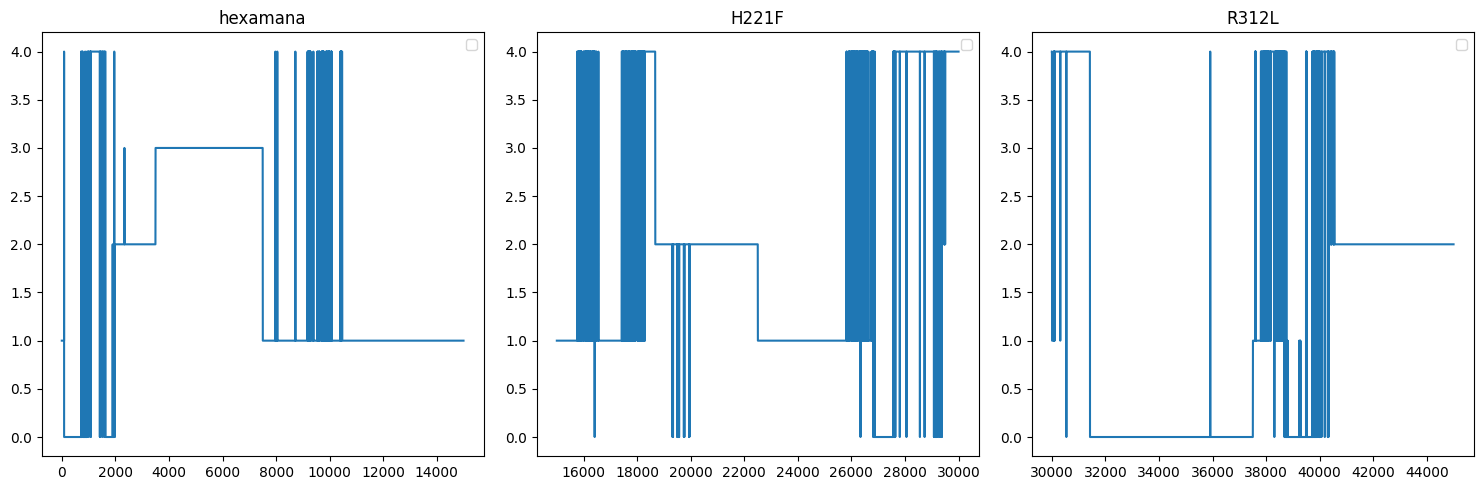

In [6]:
import os
import matplotlib.pyplot as plt
import numpy as np
os.chdir("/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations")
dhexa1="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/hexamana/correct_set/h_109/gromacs"
nhexa1=7500
dhexa2="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/hexamana/correct_set/no_h_109/gromacs"
nhexa2=7500
dHF1="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/H221F_hexamana/correct_set/h_109/gromacs"
nHF1=7500
dHF2="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/H221F_hexamana/correct_set/no_h_109/gromacs"
nHF2=7500
dRL1="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/R312L_hexamana/correct_set/h_109/gromacs"
nRL1=7500
dRL2="/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations/R312L_hexamana/correct_set/no_h_109/gromacs"
nRL2=7500
#kmeans=KMeans(n_clusters=4)ggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggggg
#clusters = kmeans.fit(combined_data
labels_test=np.load("labels_test.npy")
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
x=[]
j=0
for i in range (0,(nhexa1+nhexa2+nHF1+nHF2+nRL1+nRL2)):

    j=j+1
    x.append(i)
# Plot in the first subplot
axs[0].plot(x[0:(nhexa1+nhexa2)], labels_test[0:(nhexa1+nhexa2)])
axs[0].set_title('hexamana')
axs[0].legend()

# Plot in the second subplot
axs[1].plot(x[(nhexa1+nhexa2):(nhexa1+nhexa2+nHF1+nHF2)], labels_test[(nhexa1+nhexa2):(nhexa1+nhexa2+nHF1+nHF2)])
axs[1].set_title('H221F')
axs[1].legend()

# Plot in the third subplot
axs[2].plot(x[(nhexa1+nhexa2+nHF1+nHF2):(nhexa1+nhexa2+nHF1+nHF2+nRL1+nRL2)], labels_test[(nhexa1+nhexa2+nHF1+nHF2):(nhexa1+nhexa2+nHF1+nHF2+nRL1+nRL2)])
axs[2].set_title('R312L')
axs[2].legend()

# Add space between subplots
plt.tight_layout()

# Add a main title to the entire figure
#plt.suptitle('K-Means')

# Show the plot
#In this example, we use plt.subplots to create a 1x3 grid of subplots within a single figure. We then plot different functions in each subplot using the individual axs objects. The figsize parameter in the plt.subplots function determines the size of the entire figure. The plt.tight_layout() function is used to add spacing between the subplots, and plt.suptitle() adds a main title to the entire figure.
plt.savefig("GMVAE.jpg")
plt.show()

In [12]:
!ls

backend_GMVAE						    slurm-2853978.out
bin							    slurm-2854553.out
charmm-gui-Asp-123					    slurm-2854558.out
charmm-gui-no-Asp					    slurm-2855309.out
cuda-repo-debian11-11-8-local_11.8.0-520.61.05-1_amd64.deb  slurm-2855541.out
cuda-repo-rhel7-11-8-local-11.8.0_520.61.05-1.x86_64.rpm    slurm-2856596.out
dyn.csh							    slurm-2856618.out
dysamplegeneration.sh					    slurm-2856627.out
final_production.xtc					    slurm-2856651.out
first-dyn.csh						    slurm-2856657.out
fourha.pdb						    slurm-2856658.out
GMVAE.py						    slurm-2856666.out
gromacs-2019.4						    slurm-2856681.out
H221F_fourha						    slurm-2856814.out
H221F_hexamana						    slurm-2859167.out
H221F_tetraha						    slurm-2859190.out
hexamana						    slurm-2859211.out
include							    slurm-2859462.out
lib64							    slurm-2860484.out
miniconda						    slurm-2860485.out
miniconda.sh						    slurm-2860486.out
ML.yml							    slurm-2860627.out
protein_ligand.gro					    slurm-2860631.out
py3.py		

In [ ]:
import MDAnalysis as mda
import numpy as np
#import pandas as pd
#u=mda.Universe("step4.1_equilibration.gro","final_production.xtc")
#from MDAnalysis.analysis import rms, diffusionmap, align
from MDAnalysis.analysis.distances import dist
from MDAnalysis.analysis.hydrogenbonds.hbond_analysis import HydrogenBondAnalysis as HBA
#u=mda.Universe("protein_ligand.gro","final_production.xtc")
import MDAnalysis as mda
from MDAnalysis.analysis import distances
#from sklearn.cluster import KMeans
#from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import numpy as np
import argparse
import random
#from torchvision import datasets, t:wransforms
from torch.utils.data.sampler import SubsetRandomSampler
import torch.utils.data
from scipy.io import loadmat
#from backend_GMVAE.backend_GMVAE import GMVAE
import matplotlib.pyplot as plt
import os
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

def calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection,dr,num):
    # Load the topology and trajectory files
    os.chdir(dr)
    current_working_directory=os.getcwd()
    u = mda.Universe(topology_file, trajectory_file)

    # Select the protein residues and ligand atoms
    protein_residues = u.select_atoms(protein_selection)
    ligand_atoms = u.select_atoms(ligand_selection)

    # Create an empty list to store the distances
    num_residues=len(protein_residues)
    avg_distance=np.zeros(num_residues)
    v=0
    # Iterate over all frames in the trajectory
    for ts in u.trajectory:
        # Calculate distances between protein residues and ligand atoms
        dist = distances.distance_array(protein_residues.positions, ligand_atoms.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])

        # Average the distances for each residue
        avg_dist_per_residue = dist.mean(axis=1)

        # Add the average distances to the overall list
        avg_distance=np.add(avg_distance,avg_dist_per_residue)
        v=v+1
        if v>num:
            break
    # Calculate the overall average distance
    average_distance = avg_distance

    return average_distance

topology_file = 'step4.1_equilibration.gro'
trajectory_file = 'step5_production.xtc'
new_topology_file = 'step4.1_equilibration.gro'
trajectory_file = 'step5_production.xtc'
protein_selection = 'name CA and protein'  # Atom selection for the protein residues
ligand_selection = 'resname BGLCA or resname BGLCN'  # Atom selection for the ligand
dfourha1="/expanse/lustre/projects/mda123/kmondal/fresh_folder/fourha_mutation/fourha_beta/h_123/gromacs"
nfourha1=7500
dfourha2="/expanse/lustre/projects/mda123/kmondal/fresh_folder/fourha_mutation/fourha_beta/noh_123/gromacs"
nfourha2=7500
dHFha1="/expanse/lustre/projects/mda123/kmondal/fresh_folder/fourha_mutation/H221F_fourha_beta/h_123/gromacs"
nHFha1=7500
dHFha2="/expanse/lustre/projects/mda123/kmondal/fresh_folder/fourha_mutation/H221F_fourha_beta/noh_123/gromacs"
nHFha2=7500
average_fourha1 = calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection,dfourha1,nfourha1)
average_fourha2 = calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection,dfourha2,nfourha2)
average_HF1 = calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection,dHFha1,nHFha1)
average_HF2 = calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection,dHFha2,nHFha2)
matrices = [average_fourha1,
            average_fourha2,
            average_HF1,
            average_HF2]
#matrices=[average_MMMM2]
# Initialize the result matrix
result = np.zeros_like(matrices[0])

# Add the matrices
for matrix in matrices:
    result = np.add(result, matrix)
#result=result/nMMMM2
result=result/(nfourha1+nfourha2+nHFha1+nHFha2)
def standardize_columns(matrix):
    matrix_max = np.max(matrix, axis=0)
    matrix_min = np.min(matrix, axis=0)
    standardized_matrix = (matrix - mean) / std
    return standardized_matrix



def find_elements_less_than(arr, threshold):
    indices = np.where(arr < threshold)[0]
    elements = arr[indices]
    return indices, elements

# Example usage
threshold_value = 25
print (result)
indices, elements = find_elements_less_than(result, threshold_value)
print("Indices:", indices)
print("Elements:", elements)

sel = f"name CA and resid {' '.join(map(str, indices))}"
BGLCN_1="resname BGLCN and resid 1"
BGLCA_2="resname BGLCA and resid 2"
BGLCN_3="resname BGLCN and resid 3"
BGLCA_4="resname BGLCA and resid 4"
BGLCN_5="resname BGLCN and resid 5"
BGLCA_6="resname BGLCA and resid 6"
BGLCN_7="resname BGLCN and resid 7"
BGLCA_8="resname BGLCA and resid 8"
structure="step4.1_equilibration.gro"
trajectory="step5_production.xtc"
data=[]
#print ("yes")
def combined_func(selection,selection_1, selection_2, selection_3, selection_4, selection_5, selection_6, selection_7, selection_8, structure, trajectory, dr, num,data):
    os.chdir(dr)
    current_working_directory=os.getcwd()
    u = mda.Universe(topology_file, trajectory_file)
    selection=u.select_atoms(selection)
    selection_1=u.select_atoms(selection_1)
    selection_2=u.select_atoms(selection_2)
    selection_3=u.select_atoms(selection_3)
    selection_4=u.select_atoms(selection_4)
    selection_5=u.select_atoms(selection_5)
    selection_6=u.select_atoms(selection_6)
    selection_7=u.select_atoms(selection_7)
    selection_8=u.select_atoms(selection_8)
    v=0
    for ts in u.trajectory:
        # Calculate distances between protein residues and ligand atoms
        dist_1 = distances.distance_array(selection.positions, selection_1.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        dist_2 = distances.distance_array(selection.positions, selection_2.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        dist_3 = distances.distance_array(selection.positions, selection_3.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        dist_4 = distances.distance_array(selection.positions, selection_4.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        dist_5 = distances.distance_array(selection.positions, selection_5.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        dist_6 = distances.distance_array(selection.positions, selection_6.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        dist_7 = distances.distance_array(selection.positions, selection_7.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        dist_8 = distances.distance_array(selection.positions, selection_8.positions, box=[78.80383,78.80383,78.80383,90.,90.,90.])
        avg_dist_per_residue_1 = dist_1.mean(axis=1)
        avg_dist_per_residue_2 = dist_2.mean(axis=1)
        avg_dist_per_residue_3 = dist_3.mean(axis=1)
        avg_dist_per_residue_4 = dist_4.mean(axis=1)
        avg_dist_per_residue_5 = dist_5.mean(axis=1)
        avg_dist_per_residue_6 = dist_6.mean(axis=1)
        avg_dist_per_residue_7 = dist_7.mean(axis=1)
        avg_dist_per_residue_8 = dist_8.mean(axis=1)
        final_array=np.concatenate((avg_dist_per_residue_1, avg_dist_per_residue_2, avg_dist_per_residue_3, avg_dist_per_residue_4, avg_dist_per_residue_5, avg_dist_per_residue_6 ))
        data.append(final_array)
        v=v+1
        if (v>num):
            break
    return data
data=combined_func(sel,BGLCN_1,BGLCA_2,BGLCN_3,BGLCA_4,BGLCN_5,BGLCA_6,BGLCN_7,BGLCA_8,structure,trajectory,dfourha1,nfourha1,data)
data=combined_func(sel,BGLCN_1,BGLCA_2,BGLCN_3,BGLCA_4,BGLCN_5,BGLCA_6,BGLCN_7,BGLCA_8,structure,trajectory,dfourha2,nfourha2,data)
data=combined_func(sel,BGLCN_1,BGLCA_2,BGLCN_3,BGLCA_4,BGLCN_5,BGLCA_6,BGLCN_7,BGLCA_8,structure,trajectory,dHFha1,nHFha1,data)
data=combined_func(sel,BGLCN_1,BGLCA_2,BGLCN_3,BGLCA_4,BGLCN_5,BGLCA_6,BGLCN_7,BGLCA_8,structure,trajectory,dHFha2,nHFha2,data)
combined_data=np.stack(data,axis=0)
print ("yes")
print(combined_data.shape)

def silly(k,combined_data):
    kmeans=KMeans(n_clusters=k)
    kmeans.fit(combined_data)
    label=kmeans.predict(combined_data)
    sc=silhouette_score(combined_data, label)
    print("Silhouette Score for {}:{}".format(k,sc))
    return sc
no=[]
score=[]
for j in range (2,40):
    sc=silly(j,combined_data)
    score.append(sc)
    no.append(j)

max_element=max(score)
max_index=score.index(max_element)
m_index=max_index+2
kmeans=KMeans(n_clusters=m_index)
clusters = kmeans.fit(combined_data)


    


[38.24322825 36.19160594 34.76621883 34.73640496 31.96638919 30.25088072
 31.13177999 29.54177638 27.68902272 28.03768261 25.71130821 22.41287406
 21.42120169 18.44044771 17.51227005 15.38699746 14.43538291 14.98771074
 17.0761638  17.60214075 17.27611164 17.19944029 16.30811215 15.94849433
 15.93096666 15.96684793 18.3885314  18.9396842  21.00758811 19.2030512
 17.1973685  19.67155889 20.71417441 18.22774291 18.58838589 21.64420191
 21.29569861 19.63925448 21.43109772 23.9744686  22.16235441 20.29710798
 23.16634306 24.83384969 22.7087922  22.83556001 26.28841405 27.02869899
 25.35195827 27.16702075 30.22989872 29.96414391 29.30177297 32.1856004
 33.94346646 33.1185746  33.72363128 36.205423   37.28379391 37.55401809
 38.26384334 37.87836692 35.05748973 35.02978177 36.72337084 34.89740228
 32.16085958 33.9900753  35.01259011 31.83682623 30.8722065  33.94563659
 33.82982278 30.80337472 32.15804003 35.00387575 33.34976782 31.40674137
 28.34118626 25.43055696 27.40679451 27.54235746 26.0

/home/kmondal/miniconda3/envs/DL/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


Silhouette Score for 2:0.3271598700947933


/home/kmondal/miniconda3/envs/DL/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


KeyboardInterrupt: 

Exception ignored in: 'sklearn.cluster._k_means_common._relocate_empty_clusters_dense'
Traceback (most recent call last):
  File "<__array_function__ internals>", line 177, in where
KeyboardInterrupt: 


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


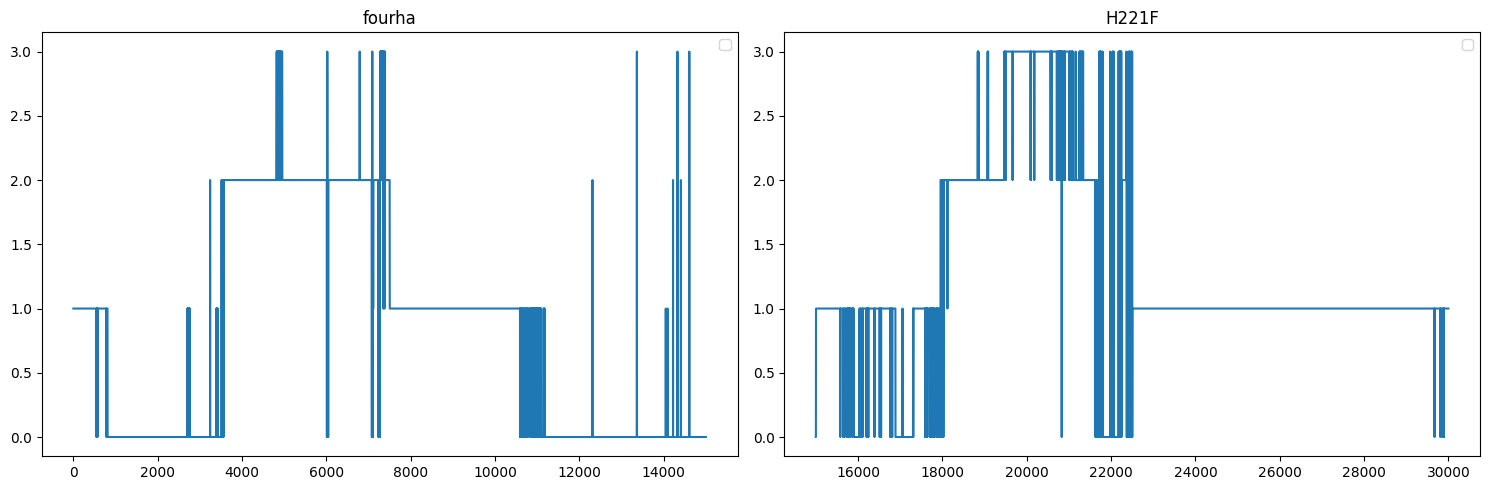

In [2]:
os.chdir("/expanse/lustre/projects/mda123/kmondal/fresh_folder/hexamana_all_mutations")
#kmeans=KMeans(n_clusters=4)
#clusters = kmeans.fit(combined_data)
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
x=[]
for i in range (0,(nfourha1+nfourha2+nHFha1+nHFha2)):

    j=j+1
    x.append(i)
# Plot in the first subplot
axs[0].plot(x[0:(nfourha1+nfourha2)], clusters.labels_[0:(nfourha1+nfourha2)])
axs[0].set_title('fourha')
axs[0].legend()

# Plot in the second subplot
axs[1].plot(x[(nfourha1+nfourha2):(nfourha1+nfourha2+nHFha1+nHFha2)], clusters.labels_[(nfourha1+nfourha2):(nfourha1+nfourha2+nHFha1+nHFha2)])
axs[1].set_title('H221F')
axs[1].legend()

# Plot in the third subplot


# Add space between subplots
plt.tight_layout()

# Add a main title to the entire figure
#plt.suptitle('K-Means')

# Show the plot
#In this example, we use plt.subplots to create a 1x3 grid of subplots within a single figure. We then plot different functions in each subplot using the individual axs objects. The figsize parameter in the plt.subplots function determines the size of the entire figure. The plt.tight_layout() function is used to add spacing between the subplots, and plt.suptitle() adds a main title to the entire figure.
plt.savefig("K-Means.jpg")
plt.show()



